# Task 1 · VRSBench Captioning — Experiment Comparison

Compares every fine-tuning run (`results/experiments/E*`) of **Qwen2.5-VL-3B-Instruct + LoRA** on the
**primary metric, BERT-BLEU₄**. It scores the saved `predictions*.json` of each run, so no GPU or re-inference is
needed — all runs were evaluated on the same validation images (checked below).

**Metric** — for each caption, with $C_n$ / $R_n$ the candidate / reference n-gram sets and $E(\cdot)$ a BERT embedding:

$$P_n = \frac{1}{|R_n|}\sum_{r\in R_n}\max_{c\in C_n}\cos\big(E(c),E(r)\big),\qquad n=1,\dots,4$$

$$\text{BERT-BLEU}_4 = LP\cdot\exp\Big(\tfrac14\sum_{n=1}^{4}\log P_n\Big),\qquad LP=\exp\Big(-\alpha\,\frac{|L_C-L_R|}{L_R}\Big),\ \alpha=0.5$$

The score is computed per caption and averaged over the validation set (range 0–1).

**Implementation choices** — all set in the config cell; change them there if the evaluator specifies otherwise:

| Choice | Default here |
|---|---|
| Encoder $E(\cdot)$ | `bert-base-uncased`, last hidden layer |
| n-gram embedding | each n-gram encoded on its own, mean-pooled over its word-pieces (`[CLS]`/`[SEP]` excluded) |
| $C_n$, $R_n$ | sets (duplicates removed), as in the metric definition |
| Tokens and lengths $L_C$, $L_R$ | lower-cased words, punctuation removed |

All runs use greedy decoding here (E8 included), so only the training differs. Also reported, from each run's `metrics*.json`: BLEU-4 and BERTScore F1 (converted from ×100 to 0–1), val loss,
training time, peak GPU memory, and trainable LoRA parameters (read from the adapter file header).

## 1. Setup

In [1]:
# Colab / Kaggle: uncomment if needed
# !pip install -q torch transformers pandas matplotlib jinja2

In [2]:
import json, math, os, re, struct
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import display
from transformers import AutoTokenizer, AutoModel

# ---- Metric config (confirm with the evaluator; change only here) ----
BERT_MODEL = 'bert-base-uncased'   # encoder for E(.)
LAYER = -1                         # hidden layer used for n-gram embeddings
POOLING = 'mean'                   # 'mean' over word-pieces, or 'cls'
USE_SETS = True                    # metric defines C_n, R_n as n-gram *sets*
ALPHA = 0.5                        # length-penalty strength
MAX_N = 4

# ---- Run config ----
N_BOOT = 2000                      # bootstrap resamples for confidence intervals
SEED = 0
BATCH_SIZE = 512
DEVICE = 'cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu'
BASELINE = 'E0'

RUN_NOTES = {
    'E0': 'Baseline',
    'E1': 'Resolution + GC',
    'E2': 'Last 8 Vision LoRA',
    'E3': 'All 32 Vision LoRA',
    'E4': 'Scheduler',
    'E5': 'GA=2',
    'E6': '2 epochs',
    'E7': 'Rank=32',
    'E8': 'Full data + GA + cosine + DDP',
}


def find_root():
    for cand in [Path.cwd().parent / 'results' / 'experiments', Path.cwd() / 'results' / 'experiments', Path.cwd()]:
        if cand.is_dir() and any(p.is_dir() and re.match(r'E\d+', p.name) for p in cand.iterdir()):
            return cand
    raise FileNotFoundError("E* run folders not found - set ROOT = Path('...') manually")


ROOT = find_root()
OUT = ROOT.parent / 'comparison'
OUT.mkdir(exist_ok=True)
torch.manual_seed(SEED)
print('runs folder :', os.path.relpath(ROOT))
print('outputs     :', os.path.relpath(OUT))
print('device      :', DEVICE)

/opt/miniconda3/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


runs folder : ../results/experiments
outputs     : ../results/comparison
device      : mps


In [3]:
def run_id(folder):
    m = re.match(r'E(\d+)', folder.name)
    return int(m.group(1)) if m else None


def pick(folder, pattern, recursive=False):
    files = sorted(folder.rglob(pattern) if recursive else folder.glob(pattern))
    if len(files) > 1:
        print(f'[warn] {folder.name}: {len(files)} files match {pattern}, using {files[0].name}')
    return files[0] if files else None


runs = {}
for folder in sorted((p for p in ROOT.iterdir() if p.is_dir() and run_id(p) is not None), key=run_id):
    runs[f'E{run_id(folder)}'] = dict(
        preds=pick(folder, '*predictions*.json'),
        metrics=pick(folder, '*metrics*.json'),
        adapter=pick(folder, '*.safetensors', recursive=True),
    )

pd.DataFrame({name: {k: str(v.relative_to(ROOT)) if v else '-' for k, v in r.items()} for name, r in runs.items()}).T

,preds,metrics,adapter
E0,E0/predictions.json,E0/metrics.json,-
E1,E1/predictions.json,E1/metrics.json,-
E2,E2/predictions.json,E2/metrics.json,-
E3,E3/predictions.json,E3/metrics.json,-
E4,E4/predictions.json,E4/metrics.json,-
E5,E5/predictions.json,E5/metrics.json,-
E8,E8/predictions.json,E8/metrics.json,-


In [4]:
preds = {name: json.load(open(r['preds'])) for name, r in runs.items() if r['preds']}

# E0-E5 saved wrong image_ids: their notebooks zipped the predictions with val_records instead of val_subset.
# Reference and prediction are still paired correctly and in val_subset order, so the true ids are restored
# by position from val_subset_200.json (the 200 sampled val images, rebuilt from VRSBench_EVAL_Cap.json).
subset_file = ROOT / 'val_subset_200.json'
if subset_file.exists():
    subset = json.load(open(subset_file))
    for name, rows in preds.items():
        same_order = len(rows) == len(subset) and all(r['reference'] == s['reference'] for r, s in zip(rows, subset))
        fixed = sum(r['image_id'] != s['image_id'] for r, s in zip(rows, subset)) if same_order else 0
        if fixed:
            for r, s in zip(rows, subset):
                r['image_id'] = s['image_id']
            print(f'{name}: restored {fixed} image_ids')

# Every run must be scored on the same images against the same references
ref_of = {p['image_id']: p['reference'] for p in next(iter(preds.values()))}
for name, rows in preds.items():
    assert {p['image_id'] for p in rows} == set(ref_of), f'{name}: different validation images'
    assert all(ref_of[p['image_id']] == p['reference'] for p in rows), f'{name}: different references'

IMAGE_IDS = sorted(ref_of)
REFS = [ref_of[i] for i in IMAGE_IDS]
CANDS = {}
for name, rows in preds.items():
    pred_of = {p['image_id']: p['prediction'] for p in rows}
    CANDS[name] = [pred_of[i] for i in IMAGE_IDS]
RUNS = list(CANDS)
assert BASELINE in RUNS, f'baseline {BASELINE} not found'

print(f'{len(RUNS)} runs x {len(IMAGE_IDS)} validation captions, aligned on identical references: {RUNS}')

7 runs x 200 validation captions, aligned on identical references: ['E0', 'E1', 'E2', 'E3', 'E4', 'E5', 'E8']


## 2. BERT-BLEU₄

Every distinct n-gram (from references and all runs) is embedded exactly once, then each caption's $P_1..P_4$ is a
max-over-columns of a small cosine-similarity matrix. References are shared by all runs, so this cache avoids
re-encoding them for every run.

In [5]:
TOKEN_RE = re.compile(r"[a-z0-9]+(?:['-][a-z0-9]+)*")


def words(text):
    return TOKEN_RE.findall(text.lower())


def ngrams(ws, n):
    grams = [' '.join(ws[i:i + n]) for i in range(len(ws) - n + 1)]
    return sorted(set(grams)) if USE_SETS else grams


tok = AutoTokenizer.from_pretrained(BERT_MODEL)
bert = AutoModel.from_pretrained(BERT_MODEL).to(DEVICE).eval()


@torch.no_grad()
def embed_all(phrases):
    # Unit-norm embedding for each phrase; phrases are length-sorted by the caller to minimise padding
    out = []
    for i in range(0, len(phrases), BATCH_SIZE):
        enc = tok(phrases[i:i + BATCH_SIZE], padding=True, return_tensors='pt').to(DEVICE)
        res = bert(**enc, output_hidden_states=LAYER != -1)
        h = res.last_hidden_state if LAYER == -1 else res.hidden_states[LAYER]
        if POOLING == 'cls':
            e = h[:, 0]
        else:
            mask = enc['attention_mask'].clone()
            mask[:, 0] = 0                                                       # drop [CLS]
            mask[torch.arange(len(mask)), enc['attention_mask'].sum(1) - 1] = 0  # drop [SEP]
            mask = mask.unsqueeze(-1).to(h.dtype)
            e = (h * mask).sum(1) / mask.sum(1)
        out.append(F.normalize(e.float(), dim=-1).cpu())
    return torch.cat(out)


texts = {'ref': REFS, **CANDS}
grams = {k: [[ngrams(words(t), n) for n in range(1, MAX_N + 1)] for t in v] for k, v in texts.items()}
vocab = sorted({g for per_text in grams.values() for per_n in per_text for gs in per_n for g in gs},
               key=lambda g: (g.count(' '), len(g), g))
index = {g: i for i, g in enumerate(vocab)}
print(f'embedding {len(vocab):,} unique n-grams with {BERT_MODEL} on {DEVICE} ...')
EMB = embed_all(vocab)
print('done:', tuple(EMB.shape))

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 7142.63it/s]


[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


embedding 53,011 unique n-grams with bert-base-uncased on mps ...


done: (53011, 768)


In [6]:
def score_caption(cand_grams, ref_grams, cand_len, ref_len):
    P = []
    for Cn, Rn in zip(cand_grams, ref_grams):
        if not Cn or not Rn:                       # caption shorter than n words
            P.append(0.0)
            continue
        sim = EMB[[index[g] for g in Rn]] @ EMB[[index[g] for g in Cn]].T   # |R_n| x |C_n| cosines
        P.append(sim.max(dim=1).values.mean().item())                     # best candidate match per reference n-gram
    geo = math.exp(sum(math.log(max(p, 1e-9)) for p in P) / len(P))
    lp = math.exp(-ALPHA * abs(cand_len - ref_len) / ref_len)
    return lp * geo, lp, geo, P


ref_lens = [len(words(t)) for t in REFS]
rows = []
for name in RUNS:
    for i, text in enumerate(CANDS[name]):
        pred_len = len(words(text))
        s, lp, geo, P = score_caption(grams[name][i], grams['ref'][i], pred_len, ref_lens[i])
        rows.append(dict(run=name, image_id=IMAGE_IDS[i], bert_bleu4=s, LP=lp, geo_mean=geo,
                         **{f'P{n}': P[n - 1] for n in range(1, MAX_N + 1)},
                         pred_len=pred_len, ref_len=ref_lens[i]))

per_sample = pd.DataFrame(rows)
per_sample.to_csv(OUT / 'per_sample_scores.csv', index=False)

components = per_sample.groupby('run', sort=False)[['bert_bleu4', 'geo_mean', 'LP', 'P1', 'P2', 'P3', 'P4']].mean()
components

,bert_bleu4,geo_mean,LP,P1,P2,P3,P4
run,,,,,,,
E0,0.658637,0.780075,0.846423,0.850769,0.768958,0.749239,0.755816
E1,0.654114,0.784220,0.836949,0.856396,0.773449,0.752746,0.758883
E2,0.662530,0.780214,0.851178,0.850825,0.768392,0.749959,0.756115
E3,0.665935,0.779363,0.855886,0.851237,0.767910,0.747890,0.755001
E4,0.660009,0.784921,0.843240,0.856462,0.773688,0.753849,0.760202
E5,0.660736,0.784372,0.844496,0.856061,0.772361,0.753477,0.760076
E8,0.670031,0.785602,0.853515,0.854158,0.774850,0.756271,0.761317


## 3. Paired bootstrap — are the differences real?

200 validation captions is a small sample, so a gap of a few thousandths can be noise. Each bootstrap resample
draws 200 image indices with replacement and uses **the same indices for every run** (paired), so the image
difficulty cancels out when runs are compared.

- **CI95**: 95% confidence interval of a run's mean BERT-BLEU₄
- **Δ vs E0**: improvement over the baseline, with its own paired CI. If the Δ CI excludes 0, the gain is unlikely to be noise
- **P(best run)**: fraction of resamples in which the run has the highest score

In [7]:
rng = np.random.default_rng(SEED)
S = per_sample.pivot(index='image_id', columns='run', values='bert_bleu4')[RUNS]
M = S.to_numpy()                                         # images x runs
boot = M[rng.integers(0, len(M), size=(N_BOOT, len(M)))].mean(axis=1)   # N_BOOT x runs
b = RUNS.index(BASELINE)
delta = boot - boot[:, [b]]

ci = pd.DataFrame({
    'BERT-BLEU4': M.mean(0),
    'CI95 low': np.percentile(boot, 2.5, axis=0),
    'CI95 high': np.percentile(boot, 97.5, axis=0),
    f'Δ vs {BASELINE}': M.mean(0) - M[:, b].mean(),
    'Δ CI95 low': np.percentile(delta, 2.5, axis=0),
    'Δ CI95 high': np.percentile(delta, 97.5, axis=0),
    f'P(> {BASELINE})': (delta > 0).mean(0),
    'P(best run)': np.bincount(boot.argmax(1), minlength=len(RUNS)) / N_BOOT,
}, index=RUNS)
ci.to_csv(OUT / 'bootstrap_ci.csv')
ci.round(4)

,BERT-BLEU4,CI95 low,CI95 high,Δ vs E0,Δ CI95 low,Δ CI95 high,P(> E0),P(best run)
E0,0.6586,0.6443,0.6718,-0.0000,0.0000,0.0000,0.0000,0.008
E1,0.6541,0.6376,0.6703,-0.0045,-0.0162,0.0074,0.2530,0.004
E2,0.6625,0.6484,0.6760,0.0039,-0.0059,0.0137,0.7925,0.053
E3,0.6659,0.6520,0.6781,0.0073,-0.0029,0.0172,0.9300,0.188
E4,0.6600,0.6438,0.6749,0.0014,-0.0098,0.0131,0.6065,0.022
E5,0.6607,0.6460,0.6748,0.0021,-0.0084,0.0129,0.6525,0.030
E8,0.6700,0.6559,0.6832,0.0114,-0.0006,0.0236,0.9690,0.695


## 4. Final comparison table

In [8]:
PARAM_COUNTS = json.loads((ROOT / 'lora_param_counts.json').read_text()) if (ROOT / 'lora_param_counts.json').exists() else {}


def lora_params(path):
    # Trainable LoRA parameter count from the safetensors header (weights are not loaded)
    with open(path, 'rb') as f:
        header = json.loads(f.read(struct.unpack('<Q', f.read(8))[0]))
    header.pop('__metadata__', None)
    return sum(math.prod(t['shape']) for t in header.values())


def training_log(m):
    t = m.get('training', [])
    return t if isinstance(t, list) else [t]


table = []
for name in RUNS:
    r = runs[name]
    m = json.load(open(r['metrics'])) if r['metrics'] else {}
    log, met = training_log(m), m.get('metrics', {})
    ps = per_sample[per_sample.run == name]
    table.append({
        'run': name,
        'change': RUN_NOTES.get(name, ''),
        'BERT-BLEU4': ci.loc[name, 'BERT-BLEU4'],
        'CI95': f"[{ci.loc[name, 'CI95 low']:.4f}, {ci.loc[name, 'CI95 high']:.4f}]",
        'P(best)': ci.loc[name, 'P(best run)'],
        'geo P1-4': ps.geo_mean.mean(),
        'LP': ps.LP.mean(),
        'BLEU-4': met.get('BLEU-4', np.nan) / 100,
        'BERTScore F1': met.get('BERT_SCORE_F1', np.nan) / 100,
        'val loss': log[-1].get('val_loss', np.nan) if log else np.nan,
        'train min': sum(e.get('epoch_time_min', np.nan) for e in log) if log else np.nan,
        'peak GB': max(e.get('peak_gpu_memory_gb', np.nan) for e in log) if log else np.nan,
        'LoRA params (M)': (lora_params(r['adapter']) if r['adapter'] else PARAM_COUNTS.get(name, np.nan)) / 1e6,
        'pred words': ps.pred_len.mean(),
    })

final = pd.DataFrame(table).set_index('run')
final.to_csv(OUT / 'comparison_table.csv')
best = final['BERT-BLEU4'].idxmax()
print(f"Best on BERT-BLEU4: {best} ({RUN_NOTES.get(best, '')})   |   reference length = {np.mean(ref_lens):.1f} words")

HIGHLIGHT = 'font-weight: bold; background-color: #cde2fb; color: #0b0b0b'
fmt = {c: '{:.4f}' for c in ['BERT-BLEU4', 'P(best)', 'geo P1-4', 'LP', 'BLEU-4', 'BERTScore F1', 'val loss']}
fmt.update({'train min': '{:.1f}', 'peak GB': '{:.1f}', 'LoRA params (M)': '{:.2f}', 'pred words': '{:.1f}'})
(final.style.format(fmt, na_rep='-')
      .highlight_max(subset=['BERT-BLEU4', 'P(best)', 'geo P1-4', 'LP', 'BLEU-4', 'BERTScore F1'], props=HIGHLIGHT)
      .highlight_min(subset=['val loss', 'train min', 'peak GB'], props=HIGHLIGHT))

Best on BERT-BLEU4: E8 (Full data + GA + cosine + DDP)   |   reference length = 48.0 words


,change,BERT-BLEU4,CI95,P(best),geo P1-4,LP,BLEU-4,BERTScore F1,val loss,train min,peak GB,LoRA params (M),pred words
run,,,,,,,,,,,,,
E0,Baseline,0.6586,"[0.6443, 0.6718]",0.0080,0.7801,0.8464,0.0877,0.4555,1.4767,19.5,10.8,7.37,46.5
E1,Resolution + GC,0.6541,"[0.6376, 0.6703]",0.0040,0.7842,0.8369,0.0890,0.4421,1.4900,47.3,14.3,7.37,51.9
E2,Last 8 Vision LoRA,0.6625,"[0.6484, 0.6760]",0.0530,0.7802,0.8512,0.0958,0.4486,1.4867,21.3,11.1,8.36,47.0
E3,All 32 Vision LoRA,0.6659,"[0.6520, 0.6781]",0.1880,0.7794,0.8559,0.0978,0.4600,1.4750,27.4,13.1,11.30,45.6
E4,Scheduler,0.6600,"[0.6438, 0.6749]",0.0220,0.7849,0.8432,0.0937,0.4504,1.5108,23.2,13.7,11.30,50.7
E5,GA=2,0.6607,"[0.6460, 0.6748]",0.0300,0.7844,0.8445,0.0910,0.4552,1.5018,27.0,13.3,11.30,50.0
E8,Full data + GA + cosine + DDP,0.6700,"[0.6559, 0.6832]",0.6950,0.7856,0.8535,-,-,-,135.8,12.7,11.30,44.2


## 5. Plots

Figures are also saved as PNG in `results/comparison/`.

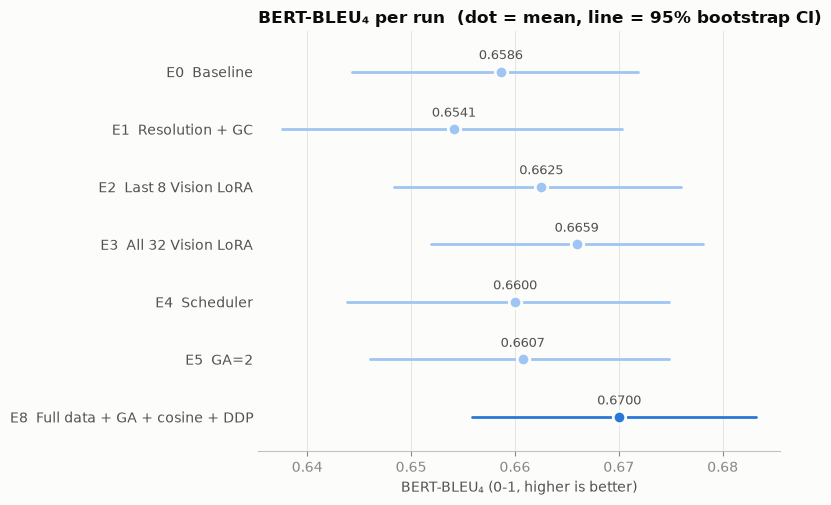

In [9]:
BLUE, BLUE_LIGHT, BLUE_PALE = '#2a78d6', '#9ec5f4', '#cde2fb'
INK, INK_2, MUTED, GRID, SURFACE = '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#fcfcfb'
plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': INK_2, 'text.color': INK,
    'xtick.color': MUTED, 'ytick.color': INK_2, 'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.spines.left': False,
    'axes.titleweight': 'bold', 'axes.titlesize': 12, 'axes.titlelocation': 'left', 'font.size': 10,
})
LABELS = [f'{r}  {RUN_NOTES.get(r, "")}' for r in RUNS]


def dot_whisker(ax, values, lows, highs, highlight, fmt='{:.4f}'):
    for y, (v, lo, hi, hl) in enumerate(zip(values, lows, highs, highlight)):
        c = BLUE if hl else BLUE_LIGHT
        ax.plot([lo, hi], [y, y], color=c, lw=2, solid_capstyle='round', zorder=2)
        ax.plot(v, y, 'o', ms=9, color=c, mec=SURFACE, mew=2, zorder=3)
        ax.annotate(fmt.format(v), (v, y), xytext=(0, 9), textcoords='offset points',
                    ha='center', fontsize=9, color=INK_2)
    ax.set_yticks(range(len(values)), LABELS)
    ax.set_ylim(len(values) - 0.4, -0.7)
    ax.grid(axis='y', visible=False)
    ax.tick_params(axis='y', length=0)


fig, ax = plt.subplots(figsize=(8, 0.55 * len(RUNS) + 1.3))
dot_whisker(ax, ci['BERT-BLEU4'], ci['CI95 low'], ci['CI95 high'], [r == best for r in RUNS])
ax.set_title('BERT-BLEU₄ per run  (dot = mean, line = 95% bootstrap CI)')
ax.set_xlabel('BERT-BLEU₄ (0-1, higher is better)')
fig.tight_layout()
fig.savefig(OUT / 'bert_bleu4_ranking.png', dpi=200)
plt.show()

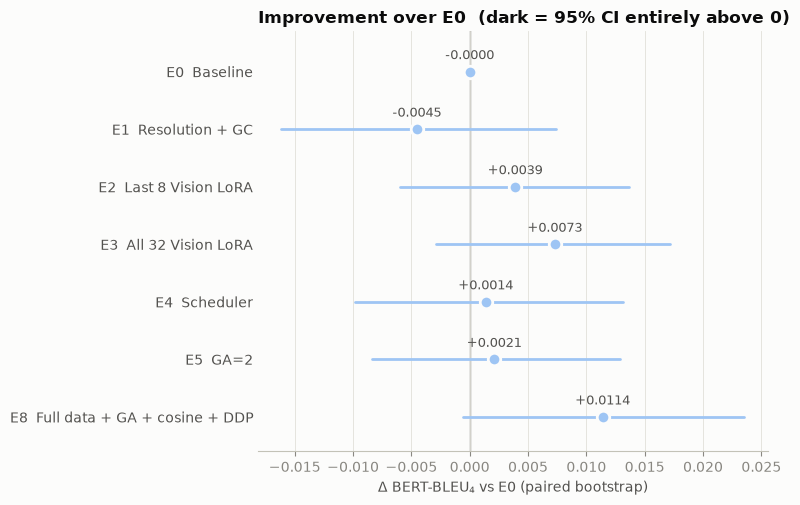

In [10]:
d = ci[f'Δ vs {BASELINE}']
significant = (ci['Δ CI95 low'] > 0).tolist()
fig, ax = plt.subplots(figsize=(8, 0.55 * len(RUNS) + 1.3))
ax.axvline(0, color=MUTED, lw=1, zorder=1)
dot_whisker(ax, d, ci['Δ CI95 low'], ci['Δ CI95 high'], significant, fmt='{:+.4f}')
ax.set_title(f'Improvement over {BASELINE}  (dark = 95% CI entirely above 0)')
ax.set_xlabel(f'Δ BERT-BLEU₄ vs {BASELINE} (paired bootstrap)')
fig.tight_layout()
fig.savefig(OUT / 'delta_vs_baseline.png', dpi=200)
plt.show()

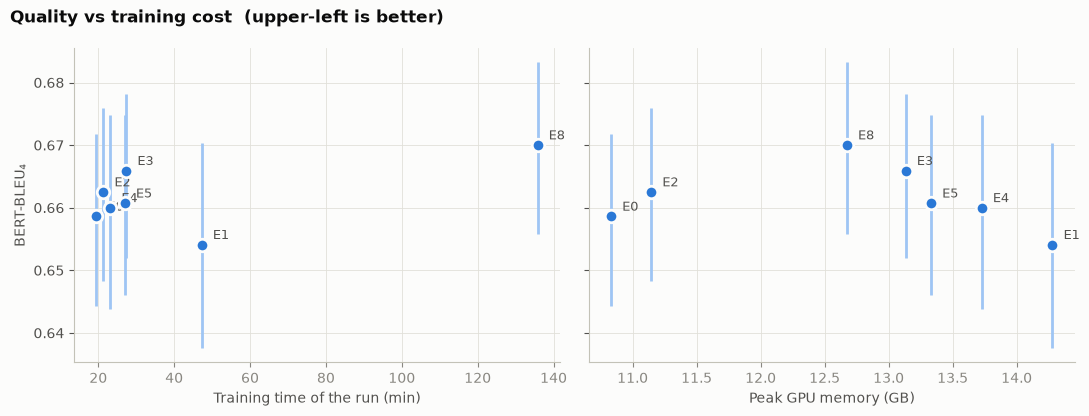

In [11]:
err = np.array([final['BERT-BLEU4'] - ci['CI95 low'], ci['CI95 high'] - final['BERT-BLEU4']])
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, col, xl in zip(axes, ['train min', 'peak GB'], ['Training time of the run (min)', 'Peak GPU memory (GB)']):
    ax.errorbar(final[col], final['BERT-BLEU4'], yerr=err, fmt='o', ms=9, color=BLUE, ecolor=BLUE_LIGHT,
                elinewidth=2, mec=SURFACE, mew=2, zorder=3)
    for r in RUNS:
        ax.annotate(r, (final.loc[r, col], final.loc[r, 'BERT-BLEU4']), xytext=(8, 4),
                    textcoords='offset points', fontsize=9, color=INK_2)
    ax.set_xlabel(xl)
    ax.spines['left'].set_visible(True)
axes[0].set_ylabel('BERT-BLEU₄')
fig.suptitle('Quality vs training cost  (upper-left is better)', fontweight='bold', x=0.01, ha='left')
fig.tight_layout()
fig.savefig(OUT / 'quality_vs_cost.png', dpi=200)
plt.show()

### What drives the score — n-gram recall vs length penalty

$P_1 \dots P_4$ show semantic recall at each n-gram order, and **LP** shows how much each run loses to caption-length
mismatch. A run can gain BERT-BLEU₄ either through better content (higher $P_n$) or through better length
matching (higher LP).

In [12]:
RAMP = LinearSegmentedColormap.from_list('ramp', ['#f4f8fe', '#9ec5f4', '#2a78d6'])
(components.rename(columns={'bert_bleu4': 'BERT-BLEU4', 'geo_mean': 'geo P1-4'})
    .style.format('{:.4f}').background_gradient(cmap=RAMP, axis=0))

,BERT-BLEU4,geo P1-4,LP,P1,P2,P3,P4
run,,,,,,,
E0,0.6586,0.7801,0.8464,0.8508,0.7690,0.7492,0.7558
E1,0.6541,0.7842,0.8369,0.8564,0.7734,0.7527,0.7589
E2,0.6625,0.7802,0.8512,0.8508,0.7684,0.7500,0.7561
E3,0.6659,0.7794,0.8559,0.8512,0.7679,0.7479,0.7550
E4,0.6600,0.7849,0.8432,0.8565,0.7737,0.7538,0.7602
E5,0.6607,0.7844,0.8445,0.8561,0.7724,0.7535,0.7601
E8,0.6700,0.7856,0.8535,0.8542,0.7749,0.7563,0.7613


,pred words,ref words,"corr(pred, ref length)",% longer than ref,% LP < 0.8,mean LP
run,,,,,,
E0,46.485,47.96,0.236,49.5,23.5,0.846
E1,51.860,47.96,0.223,59.5,25.5,0.837
E2,46.980,47.96,0.311,48.5,22.0,0.851
E3,45.570,47.96,0.286,48.0,20.5,0.856
E4,50.670,47.96,0.302,60.5,23.0,0.843
E5,49.995,47.96,0.323,56.0,26.5,0.844
E8,44.215,47.96,0.294,45.0,24.0,0.854


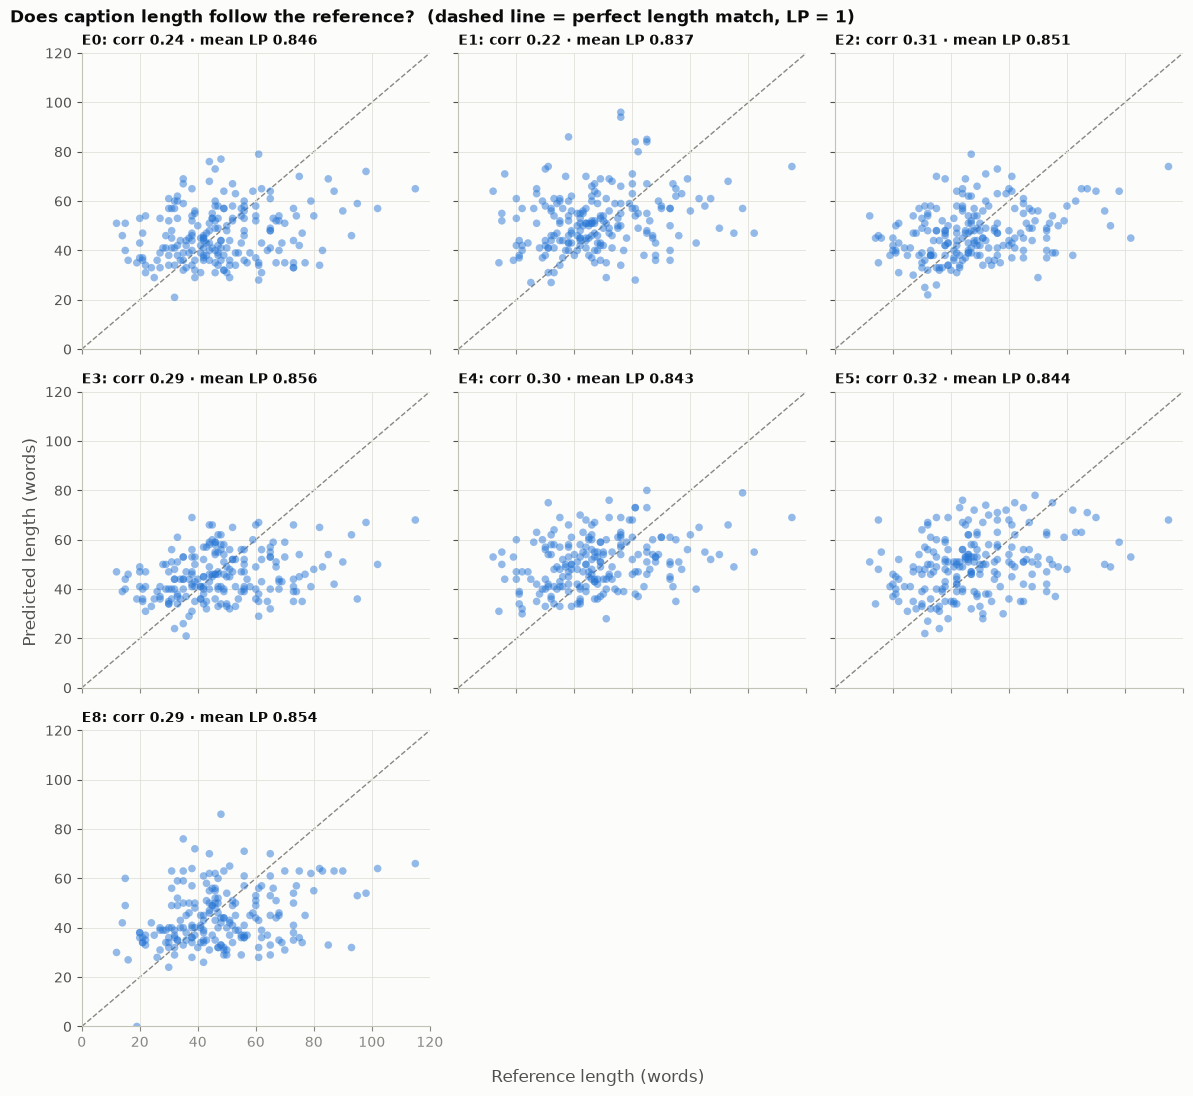

In [13]:
length = per_sample.groupby('run', sort=False).apply(lambda g: pd.Series({
    'pred words': g.pred_len.mean(),
    'ref words': g.ref_len.mean(),
    'corr(pred, ref length)': np.corrcoef(g.pred_len, g.ref_len)[0, 1],
    '% longer than ref': 100 * (g.pred_len > g.ref_len).mean(),
    '% LP < 0.8': 100 * (g.LP < 0.8).mean(),
    'mean LP': g.LP.mean(),
}), include_groups=False)
display(length.round(3))

cols = 3
rows_ = math.ceil(len(RUNS) / cols)
fig, axes = plt.subplots(rows_, cols, figsize=(4 * cols, 3.7 * rows_), sharex=True, sharey=True, squeeze=False)
lim = [0, max(per_sample.pred_len.max(), per_sample.ref_len.max()) + 5]
for ax, r in zip(axes.flat, RUNS):
    g = per_sample[per_sample.run == r]
    ax.plot(lim, lim, color=MUTED, lw=1, ls='--', zorder=1)
    ax.scatter(g.ref_len, g.pred_len, s=30, color=BLUE, alpha=0.5, edgecolors='none', zorder=2)
    ax.set_title(f"{r}: corr {length.loc[r, 'corr(pred, ref length)']:.2f} · mean LP {g.LP.mean():.3f}", fontsize=10)
    ax.set_xlim(lim)
    ax.set_ylim(lim)
    ax.spines['left'].set_visible(True)
for ax in axes.flat[len(RUNS):]:
    ax.set_visible(False)
fig.supxlabel('Reference length (words)', color=INK_2)
fig.supylabel('Predicted length (words)', color=INK_2)
fig.suptitle('Does caption length follow the reference?  (dashed line = perfect length match, LP = 1)',
             fontweight='bold', x=0.01, ha='left')
fig.tight_layout()
fig.savefig(OUT / 'length_diagnosis.png', dpi=200)
plt.show()

## 6. Qualitative examples

In [14]:
pd.set_option('display.max_colwidth', None)


def examples(ids, show_runs):
    return pd.DataFrame([{
        'image_id': i,
        'reference': ref_of[i],
        **{f'{r} [score]': f'{CANDS[r][IMAGE_IDS.index(i)]}  [{S.loc[i, r]:.3f}]' for r in show_runs},
    } for i in ids]).set_index('image_id')


print(f'Best-scored captions of {best}:')
display(examples(S[best].nlargest(3).index, [best]))
print(f'Worst-scored captions of {best} (failure cases):')
display(examples(S[best].nsmallest(3).index, [best]))
if best != BASELINE:
    print(f'Largest gains of {best} over {BASELINE}:')
    display(examples((S[best] - S[BASELINE]).nlargest(3).index, [BASELINE, best]))

Best-scored captions of E8:


,reference,E8 [score]
image_id,,
P5789_2847.png,The high-resolution grayscale image provided by GF features an urban setting with dense buildings and a unique baseball diamond located in the middle-right of the frame. The baseball diamond is small in size with a distinctive infield and outfield clearly visible.,The grayscale image provided by GF with medium resolution features an urban area with various buildings and a baseball diamond located towards the right side of the frame. The baseball diamond is distinguishable by its curved shape and the infield dirt. [0.844]
P0929_0016.png,"The high-resolution image from GoogleEarth displays a waterfront scene with two harbors and a ship. The first harbor is positioned on the upper portion of the image, while another one situated at the bottom edge. Between them, a small ship is visible, located towards the top-right area of the image.","The high-resolution image from GoogleEarth shows a section of water with two harbors and a ship. The first harbor is located at the top-right corner of the image, while the second harbor is situated towards the bottom-right corner. A small ship is positioned near the top-middle of the image, close to the first harbor. [0.838]"
06371_0000.png,This aerial image sourced from GoogleEarth features an open grassy area with a baseball field located centrally. The field has a distinct diamond shape with a brown dirt infield and green surroundings.,"The image, sourced from GoogleEarth, shows a baseball field with a dirt infield and surrounding green grass. The field is surrounded by trees and there is a curved pathway adjacent to it. [0.824]"


Worst-scored captions of E8 (failure cases):


,reference,E8 [score]
image_id,,
P1147_0073.png,A high-resolution image from GoogleEarth shows a small airplane located on a tarmac with visible markings on the ground.,!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!! [0.000]
P1086_0003.png,The high-resolution image from Google Earth showcases a recreational area with two adjacent tennis courts.,"The high-resolution image from GoogleEarth shows a recreational area with multiple tennis courts and a swimming pool. There are three tennis courts aligned horizontally, with the top-most court being the smallest among them. The bottom-most court is the largest, stretching across the width of the image. A small, rectangular swimming pool is located at the bottom-right corner of the image. [0.194]"
P0949_0007.png,The high-resolution image sourced from GoogleEarth depicts a two ships situated at the top-right corner.,"The high-resolution image from GoogleEarth shows a body of water with two ships visible. One ship is located towards the top-right corner of the image, while the other is positioned at the top-middle part of the frame. The ships are small in size and are docked near a pier. [0.285]"


Largest gains of E8 over E0:


,reference,E0 [score],E8 [score]
image_id,,,
07345_0000.png,"The image sourced from GoogleEarth shows an area with tennis courts. There are two tennis courts visible, positioned adjacently within the frame.","The high-resolution image from GoogleEarth features a section of land with two tennis courts. The courts are adjacent to each other, with one positioned towards the top-right and the other towards the bottom-right of the frame. The surrounding area includes patches of greenery and a road running along the right edge of the image. [0.398]","The image, sourced from GoogleEarth, shows two tennis courts adjacent to each other with a grassy area surrounding them. The courts have clear white lines marking their boundaries and are positioned on a paved surface. [0.637]"
P2766_0044.png,The high-resolution Google Earth image depicts a predominantly industrial area with buildings and infrastructure. Prominently featured in the image is a storage tank located towards the middle-right of the frame.,"The high-resolution image from GoogleEarth features an urban area with various buildings and vehicles. There is one large vehicle located at the bottom-right of the image, which is the only vehicle visible within this frame. The surrounding area includes multiple structures with different roof colors and sizes, indicating a dense urban environment. [0.547]","The high-resolution image from GoogleEarth shows an industrial area with various buildings and structures. A large storage tank is visible towards the right side of the image, surrounded by other industrial buildings. [0.785]"
09421_0000.png,This aerial image provided by GoogleEarth displays three tennis courts aligned horizontally.,"The high-resolution image from GoogleEarth features three tennis courts aligned horizontally with one located at the bottom of the frame and two positioned towards the top. The courts have distinct blue surfaces with white boundary lines, and there is a small basketball court situated at the bottom-most part of the image. [0.169]","The image, sourced from GoogleEarth, features three tennis courts aligned horizontally with one at the top and two at the bottom. The courts have blue surfaces with white boundary lines. [0.403]"


## 7. Summary

In [15]:
row = ci.loc[best]
print(f"Best run        : {best} - {RUN_NOTES.get(best, '')}")
print(f"BERT-BLEU4      : {row['BERT-BLEU4']:.4f}  CI95 [{row['CI95 low']:.4f}, {row['CI95 high']:.4f}]")
print(f"vs {BASELINE}        : {row[f'Δ vs {BASELINE}']:+.4f}  CI95 [{row['Δ CI95 low']:+.4f}, {row['Δ CI95 high']:+.4f}]"
      f"   P(> {BASELINE}) = {row[f'P(> {BASELINE})']:.2f}")
print(f"P(best run)     : {row['P(best run)']:.2f} of {N_BOOT} bootstrap resamples")
sig = [r for r in RUNS if r != BASELINE and ci.loc[r, 'Δ CI95 low'] > 0]
print(f"Runs significantly above {BASELINE} (Δ CI excludes 0): {', '.join(sig) if sig else 'none'}")
print()
print('Saved to', os.path.relpath(OUT))
for f in sorted(OUT.iterdir()):
    print('  -', f.name)

Best run        : E8 - Full data + GA + cosine + DDP
BERT-BLEU4      : 0.6700  CI95 [0.6559, 0.6832]
vs E0        : +0.0114  CI95 [-0.0006, +0.0236]   P(> E0) = 0.97
P(best run)     : 0.69 of 2000 bootstrap resamples
Runs significantly above E0 (Δ CI excludes 0): none

Saved to ../results/comparison
  - bert_bleu4_ranking.png
  - bootstrap_ci.csv
  - comparison_table.csv
  - delta_vs_baseline.png
  - length_diagnosis.png
  - per_sample_scores.csv
  - quality_vs_cost.png
